# Regression analysis for simulation results

In [1]:
import importlib
import subprocess

def install_if_missing(package, import_name=None):
    name = import_name or package
    if importlib.util.find_spec(name) is None:
        subprocess.run(["pip", "install", package], check=True)

In [2]:
import os
import sys
import torch
import time

base_path = "./"

from pathlib import Path
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import seaborn as sns
import pickle
install_if_missing("pyreadr")
import pyreadr

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [3]:
n_runs = 20
methods =  ["flowgem", "mice", "gain", "hyperimpute", 'missdiff', 'bayes', 'miri', 'knewimp']
regression = "linear"
Ycol = 0

In [4]:
# Define file paths
save_dir = f"{base_path}/results/realdata"
log_file = os.path.join(save_dir, 'parameter_log.csv')
impute_dir = f"{save_dir}/imputations"
metric_dir = f"{save_dir}/metrics"
init_dir = f"{save_dir}/initializations"
sim_dir = f"{base_path}/results/simulations"

In [5]:
results = torch.load(f"{sim_dir}/results_1.pt", weights_only=False)
test = results['Xhat_store']['truth_0']
Xtest = test[:, np.arange(test.shape[1]) != Ycol % test.shape[1]]
ytest = results['Xhat_store']['truth_0'][:, 0]

In [6]:
mse = {}
coef = {}
for method in methods:
    mse[method] = []
    coef[method] = []
    for run in range(n_runs):
        imputed = results["Xhat_store"][f"{method}_{run}"]

        Xtrain = imputed[:, np.arange(imputed.shape[1]) != Ycol % imputed.shape[1]]
        ytrain = imputed[:, Ycol]

        if regression == "RF":
            regr = RandomForestRegressor(random_state=run)
            regr.fit(Xtrain, ytrain)
        elif regression == "linear":
            regr = LinearRegression().fit(Xtrain, ytrain)
            coef[method].append(np.concatenate(([regr.intercept_], regr.coef_)))
        else:
            raise ValueError(f"Regression type {regression} is not defined")

        mse[method].append(mean_squared_error(regr.predict(Xtest), ytest))

/home/kremling/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/scipy/linalg/_basic.py:1450: RuntimeWarning: overflow encountered in multiply
  residuals = np.sum(x[..., n:, :] * x[..., n:, :].conj(), axis=-2)
/home/kremling/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/metrics/_regression.py:587: RuntimeWarning: overflow encountered in square
  (y_true - y_pred) ** 2, axis=0, weights=sample_weight, xp=xp
/home/kremling/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/scipy/linalg/_basic.py:1450: RuntimeWarning: overflow encountered in multiply
  residuals = np.sum(x[..., n:, :] * x[..., n:, :].conj(), axis=-2)
/home/kremling/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/metrics/_regression.py:587: RuntimeWarning: overflow encountered in square
  (y_true - y_pred) ** 2, axis=0, weights=sample_weight, xp=xp
/home/kremling/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/s

In [7]:
## MIRI does not perform well...

coef_true_np = [1/3, 1/3, 0]
rmse_coef = pd.DataFrame({method: [np.linalg.norm(c - coef_true_np) for c in coefs] for method, coefs in coef.items()})
np.sum(rmse_coef['miri']>1000)

/home/kremling/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2784: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)


np.int64(16)

In [8]:
## so we remove its results
coef.pop('miri')
mse.pop('miri')


## and compute the RMSE on the test data
results = pd.DataFrame(mse)
results = np.sqrt(results)

In [9]:
title_dict = {'gain': 'GAIN',
              'hyperimpute': 'Hyperimpute',
              'miri': 'MIRI',
              'bayes': 'Bayes',
              'flowgem': 'FLOWGEM',
              'mice': 'MICE',
              'missdiff': 'MissDiff',
              'knewimp': 'NewImp',
              'truth': 'Truth'}

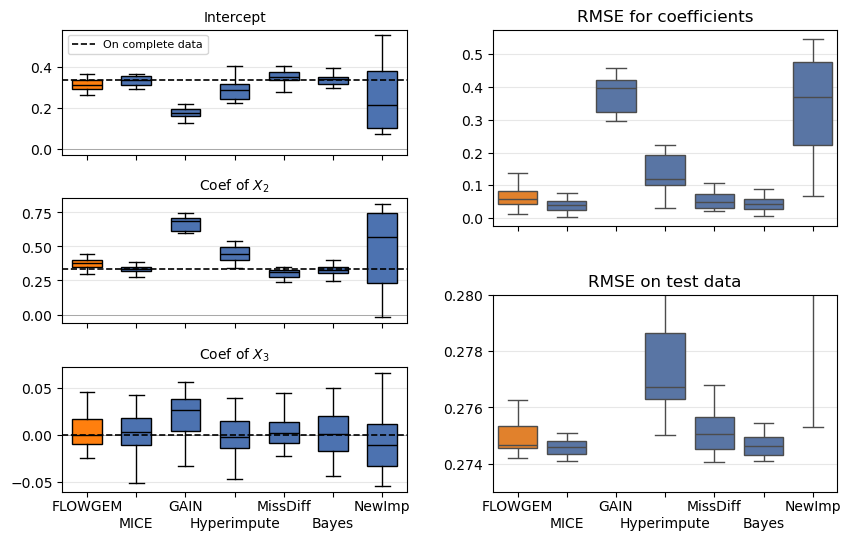

In [10]:
from matplotlib.gridspec import GridSpec

def stagger_xticklabels(ax, labels, positions, pad_low=14, pad_high=2, fontsize=None):
    """Horizontal tick labels; every other label sits lower so neighbors don't overlap."""
    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=0, ha="center", fontsize=fontsize)
    for i, tick in enumerate(ax.xaxis.get_major_ticks()):
        tick.set_pad(pad_low if i % 2 else pad_high)

def plot_coefs_and_rmse(coef_results, test_results, coef=None, coef_names=None,
                        coef_label="On complete data", coef_color="black",
                        panel_size=(5.0, 2), width_ratios=(1, 1),
                        test_ylim=None, test_ref=None,
                        show_points=False, save_path=None):
    """
    Left:  one boxplot panel per coefficient, stacked, shared x-axis.
    Right: top = L2 error of the coefficients, bottom = RMSE on test data (shared x-axis).

    coef_results: dict {method: [array_run1, array_run2, ...]}
    test_results: DataFrame (columns = methods) of test RMSEs
    coef:         true / reference coefficients (one value per coefficient)
    test_ref:     optional value drawn as a dashed line in the test panel
    """
    methods = list(coef_results.keys())
    data = {m: np.vstack(coef_results[m]) for m in methods}      # (n_runs, n_coefs)
    n_coefs = data[methods[0]].shape[1]
    if coef_names is None:
        coef_names = [f"Coef {j}" for j in range(n_coefs)]

    if coef is not None:
        coef = np.asarray(coef, dtype=float).ravel()
        if len(coef) != n_coefs:
            raise ValueError(f"coef has {len(coef)} values but results have {n_coefs} coefficients.")

    # make sure the test panel has the same methods in the same order (needed for shared x)
    test_results = test_results[methods]

    colors = ['#ff7f0e'] + ['#4C72B0'] * (len(methods) - 1)
    positions = np.arange(len(methods))                           # 0-based, like seaborn
    labels = [title_dict[m] for m in methods]
    rng = np.random.default_rng(0)

    n_rows = max(n_coefs, 2)
    fig = plt.figure(figsize=(panel_size[0] * sum(width_ratios) / width_ratios[0],
                              panel_size[1] * n_rows))
    outer = GridSpec(1, 2, figure=fig, width_ratios=width_ratios, wspace=0.25)
    gs_left = outer[0].subgridspec(n_coefs, 1, hspace=0.35)
    gs_right = outer[1].subgridspec(2, 1, hspace=0.35)

    # ---------- left: stacked coefficient panels, shared x ----------
    axes_left = []
    for j in range(n_coefs):
        ax = fig.add_subplot(gs_left[j], sharex=axes_left[0] if axes_left else None)
        axes_left.append(ax)

        vals = [data[m][:, j] for m in methods]
        bp = ax.boxplot(vals, positions=positions, widths=0.6, patch_artist=True,
                        medianprops=dict(color="black"), showfliers=False)
        for patch, c in zip(bp["boxes"], colors):
            patch.set_facecolor(c)

        if show_points:
            for i, v in zip(positions, vals):
                ax.scatter(i + rng.uniform(-0.12, 0.12, size=len(v)), v,
                           s=14, color="black", zorder=3, alpha=0.8)

        if coef is not None:
            ax.axhline(coef[j], color=coef_color, linestyle="--", linewidth=1.2,
                       label=coef_label, zorder=2)

        ax.axhline(0, color="gray", linewidth=0.5, zorder=0)
        ax.set_title(coef_names[j], fontsize=10)
        ax.grid(axis="y", alpha=0.3)
        if j < n_coefs - 1:
            ax.tick_params(labelbottom=False)

    stagger_xticklabels(axes_left[-1], labels, positions)
    if coef is not None:
        axes_left[0].legend(loc="best", fontsize=8)

    # ---------- right top: coefficient error ----------
    ax_c = fig.add_subplot(gs_right[0])
    coef_true_np = coef if coef is not None else np.zeros(n_coefs)
    rmse_coef = pd.DataFrame({
        m: [np.linalg.norm(np.asarray(c).ravel() - coef_true_np) for c in coef_results[m]]
        for m in methods
    })
    sns.boxplot(data=rmse_coef, showfliers=False, palette=colors, ax=ax_c)
    ax_c.tick_params(labelbottom=False)
    ax_c.set_title("RMSE for coefficients")
    ax_c.grid(axis="y", alpha=0.3)

    # ---------- right bottom: test RMSE (shares x with top) ----------
    ax_t = fig.add_subplot(gs_right[1], sharex=ax_c)
    palette = {m: '#4C72B0' for m in test_results.columns}
    palette['flowgem'] = '#ff7f0e'
    sns.boxplot(data=test_results, palette=palette, showfliers=False, ax=ax_t)
    stagger_xticklabels(ax_t, labels, positions)
    if test_ylim is not None:
        ax_t.set_ylim(test_ylim)
    if test_ref is not None:
        ax_t.axhline(test_ref, color="black", linestyle="dashed")
    ax_t.set_title("RMSE on test data")
    ax_t.grid(axis="y", alpha=0.3)

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
    return fig


# ---------- call ----------
fig = plot_coefs_and_rmse(
    coef,                                    # your dict {method: [arrays]}
    results,                                 # your DataFrame of test RMSEs
    coef=coef_true_np,
    coef_names=["Intercept", "Coef of $X_2$", "Coef of $X_3$"],
    test_ylim=(0.273, 0.28),
    test_ref=None,
)
plt.show()